# Ejemplo: Reducción de Dimensionalidad con el dataset Iris

## 1. Carga y exploración del dataset
Se utiliza el dataset Iris de sklearn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
print('Primeras filas:')
display(df.head())
print('Clases:', iris.target_names)

Primeras filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Clases: ['setosa' 'versicolor' 'virginica']


## 2. Visualización inicial
Visualizamos la distribución de las variables originales.

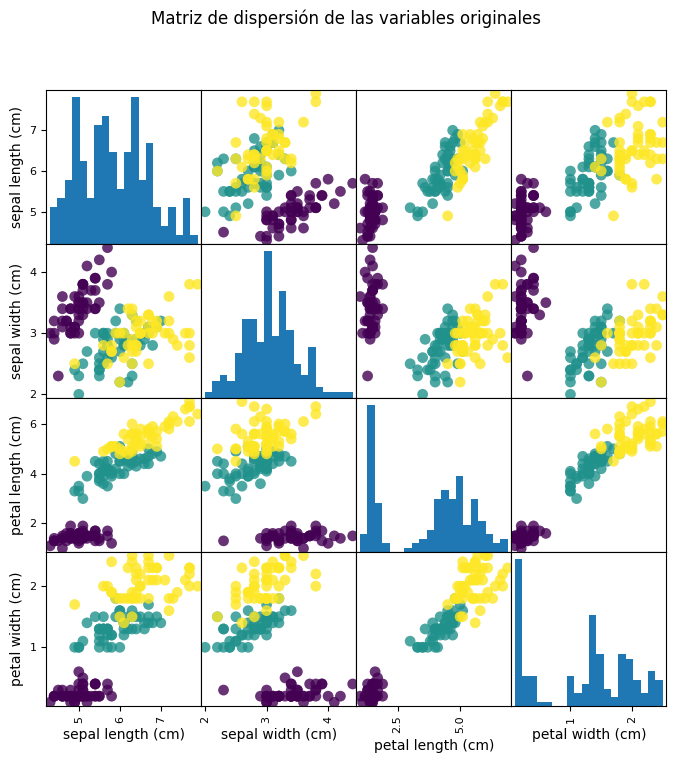

In [2]:
pd.plotting.scatter_matrix(df.iloc[:,:4], c=df['target'], figsize=(8,8), marker='o', hist_kwds={'bins':20}, s=60, alpha=.8)
plt.suptitle('Matriz de dispersión de las variables originales')
plt.show()

## 3. Reducción de dimensionalidad por transformación: PCA
Aplicamos PCA para reducir las dimensiones a 2 componentes principales.

Varianza explicada por cada componente: [0.72962445 0.22850762]


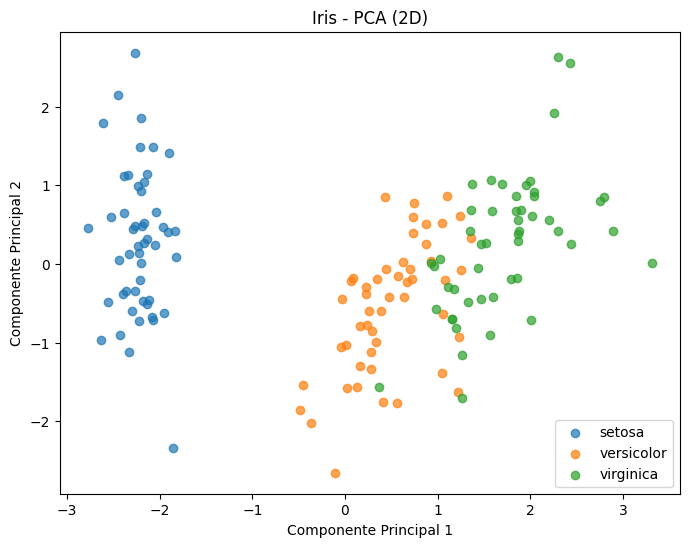

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df.iloc[:,:4]
y = df['target']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Varianza explicada por cada componente:', pca.explained_variance_ratio_)

plt.figure(figsize=(8,6))
for i, name in enumerate(iris.target_names):
    plt.scatter(X_pca[y==i,0], X_pca[y==i,1], label=name, alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Iris - PCA (2D)')
plt.legend()
plt.show()

## 4. Reducción de dimensionalidad por transformación: t-SNE
Aplicamos t-SNE para visualizar los datos en 2D.

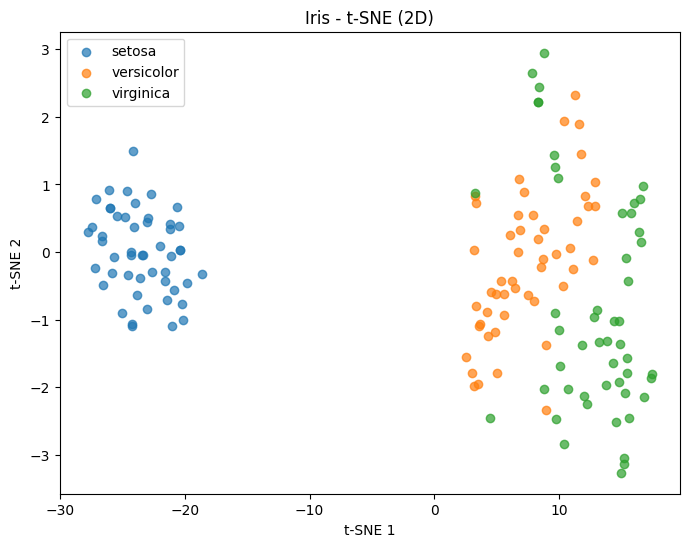

In [4]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
for i, name in enumerate(iris.target_names):
    plt.scatter(X_tsne[y==i,0], X_tsne[y==i,1], label=name, alpha=0.7)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Iris - t-SNE (2D)')
plt.legend()
plt.show()

## 5. Reducción de dimensionalidad por selección de características
Ejemplo usando filtrado por correlación.

Matriz de correlación:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


Variables seleccionadas: ['sepal width (cm)', 'sepal length (cm)']


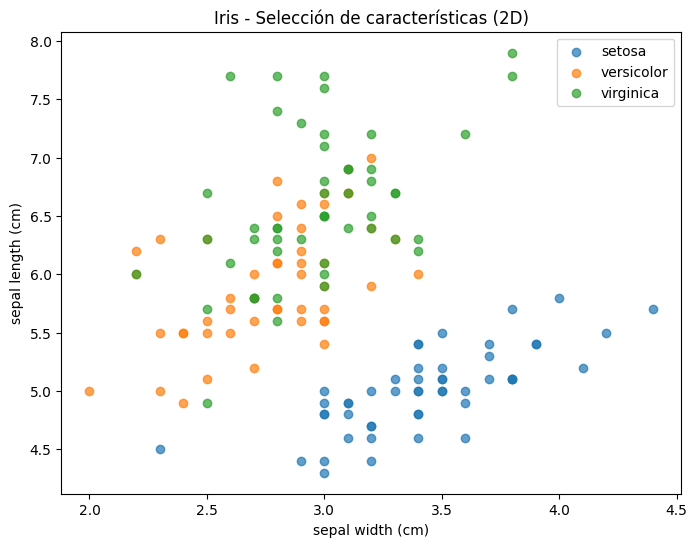

In [5]:
# Selección de características por correlación
corr = df.iloc[:,:4].corr()
print('Matriz de correlación:')
display(corr)
# Seleccionamos las dos variables menos correlacionadas
selected_features = corr.abs().sum().sort_values().index[:2]
print('Variables seleccionadas:', list(selected_features))
plt.figure(figsize=(8,6))
for i, name in enumerate(iris.target_names):
    plt.scatter(df[selected_features[0]][df['target']==i], df[selected_features[1]][df['target']==i], label=name, alpha=0.7)
plt.xlabel(selected_features[0])
plt.ylabel(selected_features[1])
plt.title('Iris - Selección de características (2D)')
plt.legend()
plt.show()

## 6. Ventajas y desventajas de los métodos
- **PCA:** Muy útil para reducir dimensiones y visualizar datos, pero los componentes no siempre son interpretables.
- **t-SNE:** Excelente para visualización, pero no preserva distancias globales y es sensible a parámetros.
- **Selección de características:** Permite mantener variables originales e interpretables, pero puede perder información relevante.

## 7. Reducción de dimensionalidad por transformación: Autoencoders
Los autoencoders son redes neuronales que aprenden una representación comprimida de los datos. Son útiles para reducción de dimensionalidad y detección de patrones no lineales.

A continuación se muestra un ejemplo sencillo usando Keras:

c:\Users\adria\miniconda3\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please update the gencode to avoid compatibility violations i

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


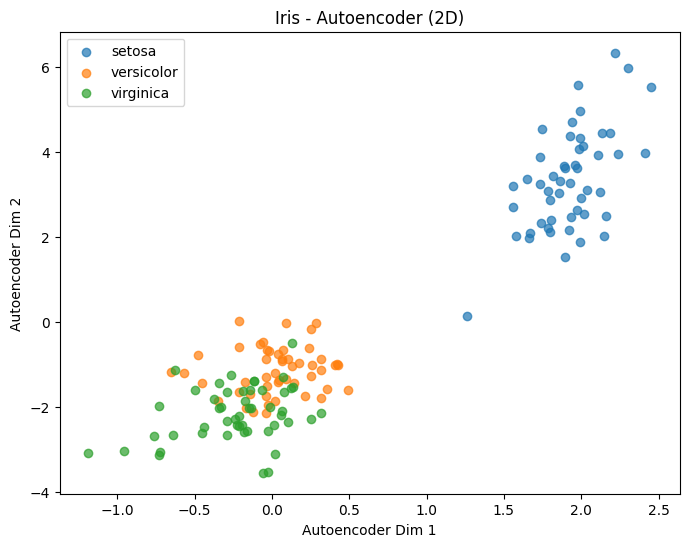

In [6]:
# Ejemplo de Autoencoder para reducción a 2 dimensiones
from tensorflow.keras.models import Model # type: ignore
from tensorflow.keras.layers import Input, Dense # type: ignore
from tensorflow.keras.optimizers import Adam # type: ignore

# Usamos los datos normalizados
input_dim = X_scaled.shape[1]
encoding_dim = 2  # Queremos reducir a 2 dimensiones

# Definición del modelo
input_layer = Input(shape=(input_dim,))
encoded = Dense(8, activation='relu')(input_layer)
encoded = Dense(encoding_dim, activation='linear')(encoded)
decoded = Dense(8, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(input_layer, decoded) # instancia 1 de model
encoder = Model(input_layer, encoded) # instancia 2 de model

autoencoder.compile(optimizer=Adam(learning_rate=0.01), loss='mse')
autoencoder.fit(X_scaled, X_scaled, epochs=100, batch_size=16, verbose=0)

X_encoded = encoder.predict(X_scaled)

plt.figure(figsize=(8,6))
for i, name in enumerate(iris.target_names):
    plt.scatter(X_encoded[y==i,0], X_encoded[y==i,1], label=name, alpha=0.7)
plt.xlabel('Autoencoder Dim 1')
plt.ylabel('Autoencoder Dim 2')
plt.title('Iris - Autoencoder (2D)')
plt.legend()
plt.show()